A decision tree asks a sequence of yes/no questions about the features until it is
confident enough to answer. The whole algorithm is one idea applied over and over:

> **Of every question I could ask, which one separates the classes best?**
> Ask it, split the data in two, then repeat on each half.

Everything below is that loop, with the arithmetic written out. The data is a
deliberately tiny EEG-flavoured table &mdash; 12 recordings &mdash; so every candidate
split can be scored on the page, not just the winner.

The chain is:

**impurity of a node &rarr; score every candidate split &rarr; take the best &rarr; recurse &rarr; leaves &rarr; prediction**

At the end the hand-built tree is compared against scikit-learn's, node for node.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from library: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

12 EEG recordings, three continuous features, and a binary label: did a seizure follow?

The table is small on purpose. A real tree searches thousands of thresholds; this one
searches 33, and all 33 are printed later.

In [2]:
# ----------------------------------------------------------------------------
#  A deliberately tiny EEG-flavoured table: 12 recordings, hand-checkable.
# ----------------------------------------------------------------------------
feature_names = ["line_length", "spike_rate", "age"]
region_names  = ["frontal", "temporal", "occipital"]

X = np.array([
    [12.0,  0.5, 24.0],
    [15.0,  1.2, 31.0],
    [42.0,  6.8, 58.0],
    [38.0,  5.1, 47.0],
    [11.0,  0.3, 19.0],
    [55.0,  8.2, 63.0],
    [40.0,  1.9, 35.0],
    [47.0,  7.4, 52.0],
    [14.0,  0.8, 28.0],
    [51.0,  6.1, 60.0],
    [45.0,  2.4, 41.0],
    [35.0,  4.7, 30.0],
])

# categorical column, used by the CatBoost notebook
region = np.array([0, 1, 1, 2, 0, 1, 2, 1, 0, 2, 0, 1])

# binary target: did a seizure follow?
y_class = np.array([0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1])

# continuous target: seizure burden in minutes/hour
y_reg = np.array([0.2, 0.5, 6.4, 4.8, 0.1, 9.1, 3.5, 7.2, 0.3, 6.9, 1.6, 4.1])

n_samples, n_features = X.shape
rec_ids = [f"rec{i:02d}" for i in range(n_samples)]

print(f"{n_samples} recordings x {n_features} features\n")
hdr = f"{'id':>6}  {'region':>10}  " + "  ".join(f"{f:>12}" for f in feature_names)
hdr += f"  {'y_class':>8}  {'y_reg':>7}"
print(hdr)
print("-" * len(hdr))
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {region_names[region[i]]:>10}  " +
          "  ".join(f"{v:>12.1f}" for v in X[i]) +
          f"  {y_class[i]:>8}  {y_reg[i]:>7.1f}")
print("-" * len(hdr))
print(f"\nclass balance: {int((y_class==0).sum())} negative, {int((y_class==1).sum())} positive")
print(f"y_reg mean = {y_reg.mean():.4f}, std = {y_reg.std():.4f}")

12 recordings x 3 features

    id      region   line_length    spike_rate           age   y_class    y_reg
-------------------------------------------------------------------------------
 rec00     frontal          12.0           0.5          24.0         0      0.2
 rec01    temporal          15.0           1.2          31.0         0      0.5
 rec02    temporal          42.0           6.8          58.0         1      6.4
 rec03   occipital          38.0           5.1          47.0         1      4.8
 rec04     frontal          11.0           0.3          19.0         0      0.1
 rec05    temporal          55.0           8.2          63.0         1      9.1
 rec06   occipital          40.0           1.9          35.0         1      3.5
 rec07    temporal          47.0           7.4          52.0         1      7.2
 rec08     frontal          14.0           0.8          28.0         0      0.3
 rec09   occipital          51.0           6.1          60.0         1      6.9
 rec10     f

---
# 2. Gini Impurity

A node is **pure** when every sample in it has the same label. Gini impurity measures
how far from pure a node is:

$$G = 1 - \sum_{k} p_k^2$$

where $p_k$ is the fraction of samples in the node belonging to class $k$.

Read it as a probability: $G$ is the chance that two samples drawn at random from the
node (with replacement) have **different** labels.

* all one class &rarr; $p = 1$ &rarr; $G = 1 - 1 = 0$ (pure)
* 50/50 split &rarr; $G = 1 - 0.5^2 - 0.5^2 = 0.5$ (worst possible for 2 classes)

In [3]:
def gini(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    p = counts / counts.sum()
    return float(1.0 - np.sum(p ** 2))

n0 = int((y_class == 0).sum())
n1 = int((y_class == 1).sum())
n  = len(y_class)

print("ROOT NODE - all 12 recordings\n")
print(f"   class 0 (no seizure): {n0} samples   ->  p_0 = {n0}/{n} = {n0/n:.6f}")
print(f"   class 1 (seizure)   : {n1} samples   ->  p_1 = {n1}/{n} = {n1/n:.6f}")
print()
print(f"   G = 1 - p_0^2 - p_1^2")
print(f"     = 1 - ({n0/n:.6f})^2 - ({n1/n:.6f})^2")
print(f"     = 1 - {(n0/n)**2:.6f} - {(n1/n)**2:.6f}")
print(f"     = {gini(y_class):.6f}")

G_root = gini(y_class)
print(f"\nRoot impurity G_root = {G_root:.6f}")
print(f"(0 would be pure, 0.5 is the worst case for two classes - this node is")
print(f" close to the worst case, which is why there is a lot to gain by splitting.)")

ROOT NODE - all 12 recordings

   class 0 (no seizure): 5 samples   ->  p_0 = 5/12 = 0.416667
   class 1 (seizure)   : 7 samples   ->  p_1 = 7/12 = 0.583333

   G = 1 - p_0^2 - p_1^2
     = 1 - (0.416667)^2 - (0.583333)^2
     = 1 - 0.173611 - 0.340278
     = 0.486111

Root impurity G_root = 0.486111
(0 would be pure, 0.5 is the worst case for two classes - this node is
 close to the worst case, which is why there is a lot to gain by splitting.)


### What impurity looks like

For two classes, Gini depends only on $p_1$. It is zero at both ends and peaks in the
middle &mdash; a node that is 50/50 is maximally uninformative.

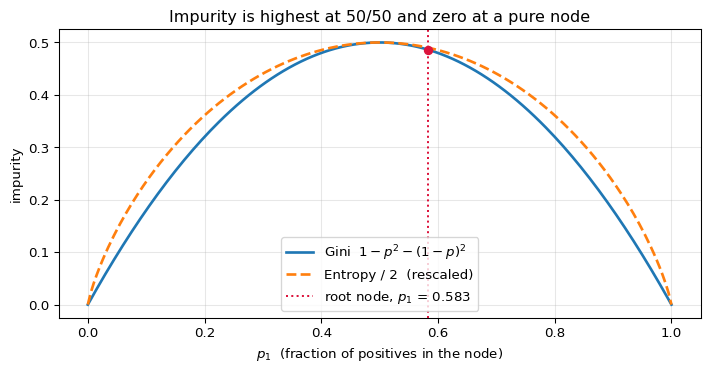

Both curves have the same shape and the same zeros, which is why swapping
Gini for entropy usually changes very little. Gini avoids the logarithm,
so it is the cheaper default.


In [4]:
p = np.linspace(0, 1, 201)
gini_curve = 1 - p**2 - (1-p)**2
ent_curve  = -(np.where(p > 0, p, 1) * np.log2(np.where(p > 0, p, 1))
               + np.where(p < 1, 1-p, 1) * np.log2(np.where(p < 1, 1-p, 1)))

plt.figure(figsize=(7.5, 4))
plt.plot(p, gini_curve, lw=2, label="Gini  $1 - p^2 - (1-p)^2$")
plt.plot(p, ent_curve / 2, lw=2, ls="--", label="Entropy / 2  (rescaled)")
plt.axvline(n1/n, color="crimson", ls=":", lw=1.5,
            label=f"root node, $p_1$ = {n1/n:.3f}")
plt.scatter([n1/n], [G_root], color="crimson", zorder=5)
plt.xlabel("$p_1$  (fraction of positives in the node)")
plt.ylabel("impurity")
plt.title("Impurity is highest at 50/50 and zero at a pure node")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("Both curves have the same shape and the same zeros, which is why swapping")
print("Gini for entropy usually changes very little. Gini avoids the logarithm,")
print("so it is the cheaper default.")

---
# 3. Scoring One Candidate Split

A split is a feature and a threshold: *is `spike_rate` $\le 3.55$?* It sends every
sample either left or right. The quality of the split is how much impurity it removes:

$$G_{\text{children}} = \frac{n_L}{n}G_L + \frac{n_R}{n}G_R
\qquad\qquad
\text{Gain} = G_{\text{parent}} - G_{\text{children}}$$

The children are weighted by **size**, not counted equally &mdash; a pure child holding one
sample is worth far less than a pure child holding six.

Candidate thresholds are the **midpoints between consecutive distinct values** of a
feature. Anything between two observed values separates the data identically, so the
midpoint is the natural representative.

In [5]:
def split_score(X, y, feat, thr):
    left  = X[:, feat] <= thr
    right = ~left
    nL, nR = int(left.sum()), int(right.sum())
    gL, gR = gini(y[left]), gini(y[right])
    weighted = (nL / len(y)) * gL + (nR / len(y)) * gR
    return gini(y) - weighted, weighted, (nL, gL), (nR, gR)


feat, thr = 1, 3.55        # spike_rate <= 3.55
left = X[:, feat] <= thr
gain, weighted, (nL, gL), (nR, gR) = split_score(X, y_class, feat, thr)

print(f"CANDIDATE SPLIT:  {feature_names[feat]} <= {thr}\n")
print(f"{'id':>6}  {feature_names[feat]:>12}  {'goes':>6}  {'y':>3}")
print("-" * 34)
for i in range(n_samples):
    print(f"{rec_ids[i]:>6}  {X[i, feat]:>12.1f}  {'LEFT' if left[i] else 'RIGHT':>6}  {y_class[i]:>3}")
print("-" * 34)

yL, yR = y_class[left], y_class[~left]
print(f"\nLEFT  ({nL} samples): labels {yL}")
print(f"   p_0 = {(yL==0).sum()}/{nL} = {(yL==0).mean():.6f},  "
      f"p_1 = {(yL==1).sum()}/{nL} = {(yL==1).mean():.6f}")
print(f"   G_L = 1 - {(yL==0).mean():.6f}^2 - {(yL==1).mean():.6f}^2 = {gL:.6f}")

print(f"\nRIGHT ({nR} samples): labels {yR}")
print(f"   p_0 = {(yR==0).sum()}/{nR} = {(yR==0).mean():.6f},  "
      f"p_1 = {(yR==1).sum()}/{nR} = {(yR==1).mean():.6f}")
print(f"   G_R = 1 - {(yR==0).mean():.6f}^2 - {(yR==1).mean():.6f}^2 = {gR:.6f}"
      f"   <- PURE" if gR == 0 else "")

print(f"\nweighted child impurity:")
print(f"   ({nL}/{n_samples}) * {gL:.6f}  +  ({nR}/{n_samples}) * {gR:.6f}")
print(f"   = {nL/n_samples:.6f} * {gL:.6f}  +  {nR/n_samples:.6f} * {gR:.6f}")
print(f"   = {(nL/n_samples)*gL:.6f} + {(nR/n_samples)*gR:.6f} = {weighted:.6f}")
print(f"\nGAIN = G_root - weighted = {G_root:.6f} - {weighted:.6f} = {gain:.6f}")

CANDIDATE SPLIT:  spike_rate <= 3.55

    id    spike_rate    goes    y
----------------------------------
 rec00           0.5    LEFT    0
 rec01           1.2    LEFT    0
 rec02           6.8   RIGHT    1
 rec03           5.1   RIGHT    1
 rec04           0.3    LEFT    0
 rec05           8.2   RIGHT    1
 rec06           1.9    LEFT    1
 rec07           7.4   RIGHT    1
 rec08           0.8    LEFT    0
 rec09           6.1   RIGHT    1
 rec10           2.4    LEFT    0
 rec11           4.7   RIGHT    1
----------------------------------

LEFT  (6 samples): labels [0 0 0 1 0 0]
   p_0 = 5/6 = 0.833333,  p_1 = 1/6 = 0.166667
   G_L = 1 - 0.833333^2 - 0.166667^2 = 0.277778

RIGHT (6 samples): labels [1 1 1 1 1 1]
   p_0 = 0/6 = 0.000000,  p_1 = 6/6 = 1.000000
   G_R = 1 - 0.000000^2 - 1.000000^2 = 0.000000   <- PURE

weighted child impurity:
   (6/12) * 0.277778  +  (6/12) * 0.000000
   = 0.500000 * 0.277778  +  0.500000 * 0.000000
   = 0.138889 + 0.000000 = 0.138889

GAIN = G_root

---
# 4. Searching Every Candidate Split

The tree is **greedy**: it does not plan ahead, it simply scores every
(feature, threshold) pair and takes the single best one.

With 3 features and 12 distinct values each there are $3 \times 11 = 33$ candidates.
All of them are scored below, ranked by gain.

In [6]:
def candidate_thresholds(col):
    vals = np.unique(col)
    return (vals[:-1] + vals[1:]) / 2.0


def best_split(X, y, feature_subset=None):
    """Exhaustive greedy search. Returns (gain, feature, threshold)."""
    best = (-1.0, None, None)
    feats = range(X.shape[1]) if feature_subset is None else feature_subset
    for f in feats:
        for t in candidate_thresholds(X[:, f]):
            g, *_ = split_score(X, y, f, t)
            if g > best[0]:
                best = (g, f, float(t))
    return best


rows = []
for f in range(n_features):
    for t in candidate_thresholds(X[:, f]):
        g, w, (nL, gL), (nR, gR) = split_score(X, y_class, f, t)
        rows.append((g, f, float(t), nL, gL, nR, gR, w))

print(f"All {len(rows)} candidate splits, ranked by gain\n")
hdr = (f"{'rank':>4}  {'feature':>12}  {'thr':>8}  {'nL':>3}  {'G_L':>7}  "
       f"{'nR':>3}  {'G_R':>7}  {'weighted':>9}  {'GAIN':>8}")
print(hdr); print("-" * len(hdr))
for rank, r in enumerate(sorted(rows, key=lambda z: -z[0]), 1):
    g, f, t, nL, gL, nR, gR, w = r
    star = "  <== BEST" if rank == 1 else ""
    print(f"{rank:>4}  {feature_names[f]:>12}  {t:>8.2f}  {nL:>3}  {gL:>7.4f}  "
          f"{nR:>3}  {gR:>7.4f}  {w:>9.4f}  {g:>8.4f}{star}")
print("-" * len(hdr))

bg, bf, bt = best_split(X, y_class)
print(f"\nWINNER: {feature_names[bf]} <= {bt}   (gain {bg:.6f})")
runner = sorted(rows, key=lambda z: -z[0])[1]
print(f"\nrunner-up: {feature_names[runner[1]]} <= {runner[2]:.2f}  (gain {runner[0]:.6f})")
print(f"The winner beats it outright, so the root question is unambiguous here.")
print(f"Deeper in the tree that stops being true - see section 7.")

All 33 candidate splits, ranked by gain

rank       feature       thr   nL      G_L   nR      G_R   weighted      GAIN
-----------------------------------------------------------------------------
   1    spike_rate      3.55    6   0.2778    6   0.0000     0.1389    0.3472  <== BEST
   2   line_length     25.00    4   0.0000    8   0.2188     0.1458    0.3403
   3    spike_rate      1.55    4   0.0000    8   0.2188     0.1458    0.3403
   4    spike_rate      4.90    7   0.4082    5   0.0000     0.2381    0.2480
   5           age     44.00    7   0.4082    5   0.0000     0.2381    0.2480
   6   line_length     14.50    3   0.0000    9   0.3457     0.2593    0.2269
   7    spike_rate      1.00    3   0.0000    9   0.3457     0.2593    0.2269
   8           age     29.00    3   0.0000    9   0.3457     0.2593    0.2269
   9   line_length     36.50    5   0.3200    7   0.2449     0.2762    0.2099
  10    spike_rate      2.15    5   0.3200    7   0.2449     0.2762    0.2099
  11         

### Why the winner wins

`spike_rate <= 3.55` sends all six high-spike-rate recordings into a node that is
**perfectly pure** ($G_R = 0$): every one of them had a seizure. That single question
removes most of the uncertainty in the dataset, which is exactly what the gain measures.

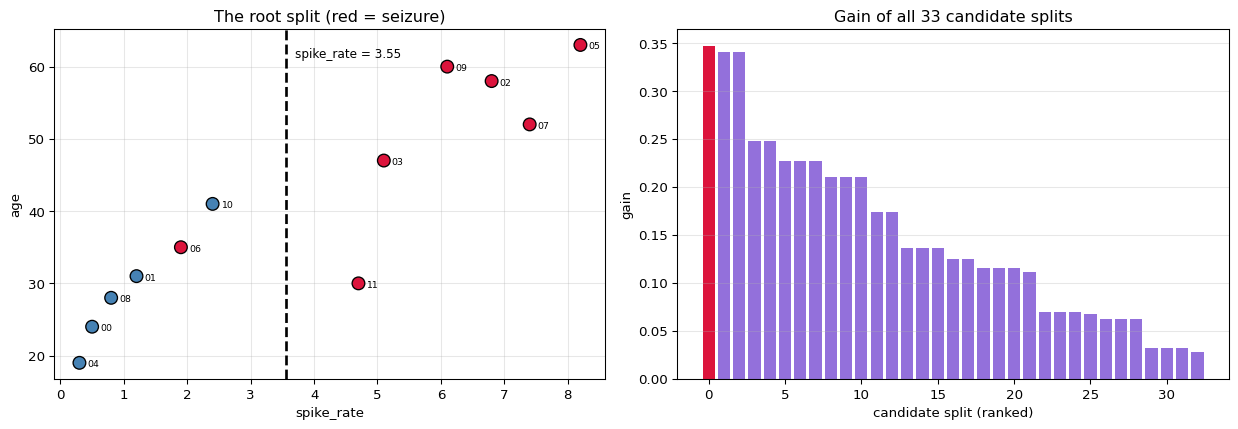

Left: one vertical line separates every high-spike-rate recording, all of
which are seizures. Right: that split's gain stands clearly above the rest.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = np.where(y_class == 1, "crimson", "steelblue")

axes[0].scatter(X[:, 1], X[:, 2], c=colors, s=90, edgecolor="k", zorder=3)
axes[0].axvline(bt, color="k", ls="--", lw=2)
axes[0].text(bt + .15, axes[0].get_ylim()[1] * .96,
             f"{feature_names[bf]} = {bt}", fontsize=9, va="top")
for i in range(n_samples):
    axes[0].annotate(rec_ids[i][3:], (X[i, 1], X[i, 2]),
                     textcoords="offset points", xytext=(6, -3), fontsize=7)
axes[0].set(xlabel="spike_rate", ylabel="age", title="The root split (red = seizure)")
axes[0].grid(alpha=.3)

ranked = sorted(rows, key=lambda z: -z[0])
axes[1].bar(range(len(ranked)), [r[0] for r in ranked], color="mediumpurple")
axes[1].bar([0], [ranked[0][0]], color="crimson")
axes[1].set(xlabel="candidate split (ranked)", ylabel="gain",
            title=f"Gain of all {len(ranked)} candidate splits")
axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

print("Left: one vertical line separates every high-spike-rate recording, all of")
print("which are seizures. Right: that split's gain stands clearly above the rest.")

---
# 5. Recursion &mdash; Growing the Whole Tree

The right child is already pure, so it becomes a **leaf**. The left child still mixes
five negatives with one positive, so the identical search runs again &mdash; but now only on
those six rows.

This is the entire algorithm: *the same function, called on smaller and smaller subsets*,
stopping when a node is pure or a limit is reached.

In [8]:
class Node:
    def __init__(self, depth, idx):
        self.depth, self.idx = depth, idx
        self.feature = self.threshold = None
        self.left = self.right = None
        self.prediction = None

    @property
    def is_leaf(self):
        return self.feature is None


def build(idx, depth=0, max_depth=3, min_samples_split=2, verbose=True):
    node = Node(depth, idx)
    y = y_class[idx]
    pad = "   " * depth
    counts = np.bincount(y, minlength=2)
    node.prediction = int(np.argmax(counts))

    if verbose:
        print(f"{pad}NODE depth={depth}  n={len(idx)}  "
              f"[{counts[0]} neg, {counts[1]} pos]  G={gini(y):.4f}")

    if gini(y) == 0.0:
        if verbose:
            print(f"{pad}   -> PURE, becomes a LEAF predicting class {node.prediction}")
        return node
    if depth >= max_depth or len(idx) < min_samples_split:
        if verbose:
            print(f"{pad}   -> stop rule hit, LEAF predicting class {node.prediction}")
        return node

    g, f, t = best_split(X[idx], y)
    if g <= 0:
        if verbose:
            print(f"{pad}   -> no split improves impurity, LEAF")
        return node

    node.feature, node.threshold = f, t
    mask = X[idx, f] <= t
    if verbose:
        print(f"{pad}   -> best split: {feature_names[f]} <= {t}  (gain {g:.4f})"
              f"  sends {int(mask.sum())} left, {int((~mask).sum())} right")
    node.left  = build(idx[mask],  depth + 1, max_depth, min_samples_split, verbose)
    node.right = build(idx[~mask], depth + 1, max_depth, min_samples_split, verbose)
    return node


print("Growing the tree, one recursive call per node:\n")
root = build(np.arange(n_samples), max_depth=3)

Growing the tree, one recursive call per node:

NODE depth=0  n=12  [5 neg, 7 pos]  G=0.4861
   -> best split: spike_rate <= 3.55  (gain 0.3472)  sends 6 left, 6 right
   NODE depth=1  n=6  [5 neg, 1 pos]  G=0.2778
      -> best split: line_length <= 27.5  (gain 0.1111)  sends 4 left, 2 right
      NODE depth=2  n=4  [4 neg, 0 pos]  G=0.0000
         -> PURE, becomes a LEAF predicting class 0
      NODE depth=2  n=2  [1 neg, 1 pos]  G=0.5000
         -> best split: line_length <= 42.5  (gain 0.5000)  sends 1 left, 1 right
         NODE depth=3  n=1  [0 neg, 1 pos]  G=0.0000
            -> PURE, becomes a LEAF predicting class 1
         NODE depth=3  n=1  [1 neg, 0 pos]  G=0.0000
            -> PURE, becomes a LEAF predicting class 0
   NODE depth=1  n=6  [0 neg, 6 pos]  G=0.0000
      -> PURE, becomes a LEAF predicting class 1


### The finished tree

Four leaves, every one of them pure. Read a path by following the answers from the top.

In [9]:
def print_tree(node, prefix="", branch=""):
    if node.is_leaf:
        y = y_class[node.idx]
        c = np.bincount(y, minlength=2)
        print(f"{prefix}{branch}LEAF  predict {node.prediction}   "
              f"n={len(node.idx)}  [{c[0]} neg, {c[1]} pos]  G={gini(y):.3f}   "
              f"{[rec_ids[i] for i in node.idx]}")
        return
    print(f"{prefix}{branch}[{feature_names[node.feature]} <= {node.threshold}] "
          f"n={len(node.idx)}  G={gini(y_class[node.idx]):.4f}")
    pad = prefix + ("    " if branch else "")
    print_tree(node.left,  pad, "|-- yes: ")
    print_tree(node.right, pad, "|-- no : ")


print_tree(root)

def depth_of(nd):
    return 0 if nd.is_leaf else 1 + max(depth_of(nd.left), depth_of(nd.right))

def leaves_of(nd):
    return 1 if nd.is_leaf else leaves_of(nd.left) + leaves_of(nd.right)

print(f"\ndepth = {depth_of(root)}, leaves = {leaves_of(root)}")
print("\nEvery leaf is pure, so this tree classifies all 12 training recordings")
print("correctly. On 12 samples that is not evidence of a good model - it is")
print("exactly the overfitting a single deep tree is prone to.")

[spike_rate <= 3.55] n=12  G=0.4861
|-- yes: [line_length <= 27.5] n=6  G=0.2778
    |-- yes: LEAF  predict 0   n=4  [4 neg, 0 pos]  G=0.000   ['rec00', 'rec01', 'rec04', 'rec08']
    |-- no : [line_length <= 42.5] n=2  G=0.5000
        |-- yes: LEAF  predict 1   n=1  [0 neg, 1 pos]  G=0.000   ['rec06']
        |-- no : LEAF  predict 0   n=1  [1 neg, 0 pos]  G=0.000   ['rec10']
|-- no : LEAF  predict 1   n=6  [0 neg, 6 pos]  G=0.000   ['rec02', 'rec03', 'rec05', 'rec07', 'rec09', 'rec11']

depth = 3, leaves = 4

Every leaf is pure, so this tree classifies all 12 training recordings
correctly. On 12 samples that is not evidence of a good model - it is
exactly the overfitting a single deep tree is prone to.


---
# 6. Prediction &mdash; Walking a Sample Down

Prediction costs almost nothing: compare, branch, repeat. A tree of depth $d$ needs at
most $d$ comparisons regardless of how much data it was trained on.

In [10]:
def predict_one(node, x, verbose=False, pad="   "):
    while not node.is_leaf:
        v, thr = x[node.feature], node.threshold
        go_left = v <= thr
        if verbose:
            print(f"{pad}is {feature_names[node.feature]} ({v:g}) <= {thr}?  "
                  f"{'YES -> left' if go_left else 'NO  -> right'}")
        node = node.left if go_left else node.right
    if verbose:
        print(f"{pad}reached a leaf -> predict class {node.prediction}")
    return node.prediction


for i in (6, 10, 5):
    print(f"rec{i:02d}: line_length={X[i,0]:g}, spike_rate={X[i,1]:g}, age={X[i,2]:g}"
          f"   (true label {y_class[i]})")
    p = predict_one(root, X[i], verbose=True)
    print(f"   predicted {p}   correct: {p == y_class[i]}\n")

preds = np.array([predict_one(root, X[i]) for i in range(n_samples)])
print(f"predictions : {preds}")
print(f"true labels : {y_class}")
print(f"training accuracy: {(preds == y_class).mean():.4f}")

rec06: line_length=40, spike_rate=1.9, age=35   (true label 1)
   is spike_rate (1.9) <= 3.55?  YES -> left
   is line_length (40) <= 27.5?  NO  -> right
   is line_length (40) <= 42.5?  YES -> left
   reached a leaf -> predict class 1
   predicted 1   correct: True

rec10: line_length=45, spike_rate=2.4, age=41   (true label 0)
   is spike_rate (2.4) <= 3.55?  YES -> left
   is line_length (45) <= 27.5?  NO  -> right
   is line_length (45) <= 42.5?  NO  -> right
   reached a leaf -> predict class 0
   predicted 0   correct: True

rec05: line_length=55, spike_rate=8.2, age=63   (true label 1)
   is spike_rate (8.2) <= 3.55?  NO  -> right
   reached a leaf -> predict class 1
   predicted 1   correct: True

predictions : [0 0 1 1 0 1 1 1 0 1 0 1]
true labels : [0 0 1 1 0 1 1 1 0 1 0 1]
training accuracy: 1.0000


---
# 7. Checking Against scikit-learn

Everything above was computed from the formulas alone. Fitting
`DecisionTreeClassifier(criterion="gini", max_depth=3)` on the same table should
reproduce the same root question, the same impurities, and the same predictions.

Deeper in the tree it will *not* match node for node &mdash; the reason is a tie, and
it is printed at the end of this section.

In [11]:
from sklearn.tree import DecisionTreeClassifier, export_text

sk = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=0)
sk.fit(X, y_class)

print("scikit-learn's tree:\n")
print(export_text(sk, feature_names=feature_names))

t = sk.tree_
print(f"{'node':>5}  {'feature':>12}  {'thr':>8}  {'n':>3}  {'impurity':>9}")
print("-" * 46)
for i in range(t.node_count):
    if t.children_left[i] == -1:
        print(f"{i:>5}  {'LEAF':>12}  {'':>8}  {int(t.n_node_samples[i]):>3}  "
              f"{t.impurity[i]:>9.6f}")
    else:
        print(f"{i:>5}  {feature_names[t.feature[i]]:>12}  {t.threshold[i]:>8.2f}  "
              f"{int(t.n_node_samples[i]):>3}  {t.impurity[i]:>9.6f}")
print("-" * 46)

print(f"\nroot feature   : ours = {feature_names[root.feature]:>12} | "
      f"sklearn = {feature_names[t.feature[0]]:>12}  "
      f"MATCH: {root.feature == t.feature[0]}")
print(f"root threshold : ours = {root.threshold:>12.4f} | "
      f"sklearn = {t.threshold[0]:>12.4f}  "
      f"MATCH: {np.isclose(root.threshold, t.threshold[0])}")
print(f"root impurity  : ours = {G_root:>12.6f} | "
      f"sklearn = {t.impurity[0]:>12.6f}  "
      f"MATCH: {np.isclose(G_root, t.impurity[0])}")
print(f"depth          : ours = {depth_of(root)}, sklearn = {int(t.max_depth)}  "
      f"MATCH: {depth_of(root) == int(t.max_depth)}")
print(f"leaf count     : ours = {leaves_of(root)}, sklearn = {int((t.children_left==-1).sum())}  "
      f"MATCH: {leaves_of(root) == int((t.children_left==-1).sum())}")
print(f"predictions    : MATCH: {np.array_equal(preds, sk.predict(X))}")

print("\n\nTIES - why the two trees are not identical deeper down\n")
L_idx = np.arange(n_samples)[X[:, root.feature] <= root.threshold]
yL_ = y_class[L_idx]
tied = []
for f in range(n_features):
    for t_ in candidate_thresholds(X[L_idx, f]):
        g_, *_ = split_score(X[L_idx], yL_, f, t_)
        tied.append((g_, f, float(t_)))
top_g = max(z[0] for z in tied)
winners = [w for w in tied if np.isclose(w[0], top_g)]
print(f"At the depth-1 left node, {len(winners)} different questions all reach the")
print(f"same best gain of {top_g:.6f}:\n")
for g_, f, t_ in winners:
    mark = "  <- ours" if (f == root.left.feature and np.isclose(t_, root.left.threshold)) else ""
    if f == t.feature[1] and np.isclose(t_, t.threshold[1]):
        mark += "  <- sklearn"
    print(f"      {feature_names[f]:>12} <= {t_:<7.2f}  gain {g_:.6f}{mark}")
print(f"\nOur search breaks the tie by lowest feature index; sklearn breaks it its own")
print(f"way. Both are valid greedy trees. What the data determines is the GAIN, not")
print(f"which of the tied questions gets asked - and since the tied splits separate")
print(f"these rows identically, the predictions come out the same either way.")

scikit-learn's tree:

|--- spike_rate <= 3.55
|   |--- age <= 33.00
|   |   |--- class: 0
|   |--- age >  33.00
|   |   |--- line_length <= 42.50
|   |   |   |--- class: 1
|   |   |--- line_length >  42.50
|   |   |   |--- class: 0
|--- spike_rate >  3.55
|   |--- class: 1

 node       feature       thr    n   impurity
----------------------------------------------
    0    spike_rate      3.55   12   0.486111
    1           age     33.00    6   0.277778
    2          LEAF              4   0.000000
    3   line_length     42.50    2   0.500000
    4          LEAF              1   0.000000
    5          LEAF              1   0.000000
    6          LEAF              6   0.000000
----------------------------------------------

root feature   : ours =   spike_rate | sklearn =   spike_rate  MATCH: True
root threshold : ours =       3.5500 | sklearn =       3.5500  MATCH: True
root impurity  : ours =     0.486111 | sklearn =     0.486111  MATCH: True
depth          : ours = 3, sklearn = 

---
# 8. Gini vs Entropy

The other common impurity measure is entropy:

$$H = -\sum_k p_k \log_2 p_k
\qquad\text{and}\qquad
\text{Information Gain} = H_{\text{parent}} - \sum_{\text{child}} \frac{n_c}{n} H_c$$

Entropy is steeper near the middle, so it slightly prefers balanced splits. In practice
the two almost always choose the same question &mdash; as they do here.

In [12]:
def entropy(y):
    if len(y) == 0:
        return 0.0
    _, c = np.unique(y, return_counts=True)
    p = c / c.sum()
    return float(-np.sum(p * np.log2(p)))

H_root = entropy(y_class)
print(f"Root:   Gini = {G_root:.6f}      Entropy = {H_root:.6f} bits")
print(f"        H = -({n0}/{n})*log2({n0}/{n}) - ({n1}/{n})*log2({n1}/{n})")
print(f"          = -{n0/n:.4f}*({np.log2(n0/n):+.4f}) - {n1/n:.4f}*({np.log2(n1/n):+.4f})")
print(f"          = {H_root:.6f}\n")

hdr = f"{'feature':>12}  {'thr':>8}  {'gini gain':>10}  {'info gain':>10}"
print(hdr); print("-" * len(hdr))
scored = []
for f in range(n_features):
    for t_ in candidate_thresholds(X[:, f]):
        L = X[:, f] <= t_
        gg = G_root - (L.mean() * gini(y_class[L]) + (~L).mean() * gini(y_class[~L]))
        ig = H_root - (L.mean() * entropy(y_class[L]) + (~L).mean() * entropy(y_class[~L]))
        scored.append((gg, ig, f, float(t_)))
for gg, ig, f, t_ in sorted(scored, key=lambda z: -z[0])[:6]:
    print(f"{feature_names[f]:>12}  {t_:>8.2f}  {gg:>10.4f}  {ig:>10.4f}")
print("-" * len(hdr))

bg_gini = max(scored, key=lambda z: z[0])
bg_ent  = max(scored, key=lambda z: z[1])
print(f"\nbest by Gini    : {feature_names[bg_gini[2]]} <= {bg_gini[3]}")
print(f"best by Entropy : {feature_names[bg_ent[2]]} <= {bg_ent[3]}")
print(f"same question?  : {(bg_gini[2], bg_gini[3]) == (bg_ent[2], bg_ent[3])}")

sk_e = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=0).fit(X, y_class)
print(f"\nsklearn with criterion='entropy' picks: "
      f"{feature_names[sk_e.tree_.feature[0]]} <= {sk_e.tree_.threshold[0]:.2f}")

Root:   Gini = 0.486111      Entropy = 0.979869 bits
        H = -(5/12)*log2(5/12) - (7/12)*log2(7/12)
          = -0.4167*(-1.2630) - 0.5833*(-0.7776)
          = 0.979869

     feature       thr   gini gain   info gain
----------------------------------------------
  spike_rate      3.55      0.3472      0.6549
 line_length     25.00      0.3403      0.6175
  spike_rate      1.55      0.3403      0.6175
  spike_rate      4.90      0.2480      0.4764
         age     44.00      0.2480      0.4764
 line_length     14.50      0.2269      0.4067
----------------------------------------------

best by Gini    : spike_rate <= 3.55
best by Entropy : spike_rate <= 3.55
same question?  : True

sklearn with criterion='entropy' picks: spike_rate <= 3.55


---
# 9. Where Trees Break

Three properties follow directly from the arithmetic above, and each one motivates
a model later in this series.

**Greedy, never revisited.** The root is chosen to be locally best and is never
reconsidered. A pair of questions that is jointly excellent but individually mediocre
will never be found.

**Axis-aligned only.** Every question has the form *feature $\le$ threshold*, so every
boundary is a vertical or horizontal cut. A diagonal boundary has to be approximated
with a staircase.

**High variance.** Every leaf here is pure &mdash; the tree memorised 12 recordings. Change
one label and the structure can change completely, as shown below.

That last property is the opening for the next notebook: if a single deep tree is
unstable, average many of them. That is a **random forest**.

In [13]:
print("Sensitivity: flip ONE label and refit\n")
base_root_q = (feature_names[root.feature], root.threshold)
print(f"original root question: {base_root_q[0]} <= {base_root_q[1]}\n")

print(f"{'flipped':>8}  {'new root question':>30}  {'changed?':>9}")
print("-" * 52)
changed = 0
for i in range(n_samples):
    y2 = y_class.copy()
    y2[i] = 1 - y2[i]
    g2, f2, t2 = best_split(X, y2)
    q = f"{feature_names[f2]} <= {t2}"
    diff = (f2, t2) != (root.feature, root.threshold)
    changed += diff
    print(f"{rec_ids[i]:>8}  {q:>30}  {'YES' if diff else 'no':>9}")
print("-" * 52)
print(f"\n{changed} of {n_samples} single-label flips change the very first question.")
print("A model this sensitive to one sample has high variance - averaging many such")
print("trees is exactly what bagging and random forests do.")

Sensitivity: flip ONE label and refit

original root question: spike_rate <= 3.55

 flipped               new root question   changed?
----------------------------------------------------
   rec00              spike_rate <= 3.55         no
   rec01             line_length <= 14.5        YES
   rec02             line_length <= 25.0        YES
   rec03             line_length <= 25.0        YES
   rec04              spike_rate <= 3.55         no
   rec05             line_length <= 25.0        YES
   rec06              spike_rate <= 3.55         no
   rec07             line_length <= 25.0        YES
   rec08              spike_rate <= 3.55         no
   rec09             line_length <= 25.0        YES
   rec10             line_length <= 25.0        YES
   rec11             line_length <= 36.5        YES
----------------------------------------------------

8 of 12 single-label flips change the very first question.
A model this sensitive to one sample has high variance - averaging many suc

---
# 10. Summary

| Stage | Formula | Result here |
|---|---|---|
| Node impurity | $G = 1 - \sum_k p_k^2$ | root $G = 0.4861$ |
| Split quality | $\frac{n_L}{n}G_L + \frac{n_R}{n}G_R$ | best $= 0.1389$ |
| Gain | $G_{\text{parent}} - G_{\text{children}}$ | $0.3472$ |
| Candidates searched | midpoints of distinct values | 33 |
| Winning question | &mdash; | `spike_rate <= 3.55` |
| Final tree | greedy recursion | depth 3, 4 pure leaves |
| Prediction cost | $\le$ depth comparisons | 3 |

**What is deliberately left out:** pruning (cost-complexity $\alpha$), missing-value
surrogate splits, multi-class targets beyond two, regression trees (variance instead of
Gini), and any form of regularisation other than `max_depth`.

**What carries forward:** every model in the rest of this series is built out of this
same greedy split search. Random forests average many of these trees; gradient boosting
machines fit them one after another to each other's errors.